# Leyenda: Deliverable 3, image captioning

## 1. Context

TouNum wants to caption its photographs automatically. The workflow has three steps: classify the image (photo or not, Deliverable 1), denoise it (Deliverable 2), then caption it. This notebook builds the captioning model and then chains the three steps.

Contents: 2 data (MS COCO), 3 text preprocessing, 4 image features, 5 the model. Training, results and the full pipeline come next.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import subprocess
import time
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from IPython.display import Image as ShowImage

from src.config import BATCH_SIZE, COCO_DIR, SEED, SUBSET_SIZE
from src.coco import choose_subset, extract_images, load_captions, save_subset_ids, split_ids

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)   # do not take all the GPU memory at once (2 GB cards)
print("GPU:", [g.name for g in gpus] or "none")
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print(f"COCO_DIR={COCO_DIR} | SUBSET_SIZE={SUBSET_SIZE} | SEED={SEED}")

I0000 00:00:1792664062.490741   97036 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792664065.274963   97036 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: ['/physical_device:GPU:0']
TensorFlow 2.21.0 | Keras 3.15.1
COCO_DIR=data/coco | SUBSET_SIZE=2000 | SEED=42


## 2. The data: MS COCO 2014

MS COCO is a dataset of photographs, each with several captions written by different people. We use the 2014 train set, from two zip files put in `data/coco/` (not versioned): the captions (250 MB) and the 82,783 images (13.5 GB). The big zip is never extracted: the captions are read inside the small one, and only the images we choose are copied out of the big one.

In [2]:
captions = load_captions()      # {image id: [captions of this image]}
print(f"{len(captions):,} images | {sum(len(c) for c in captions.values()):,} captions")
print("captions per image:", dict(sorted(Counter(len(c) for c in captions.values()).items())))

82,783 images | 414,113 captions
captions per image: {5: 82586, 6: 196, 7: 1}


Training on all the images would take too long on our machines, so we use a **subset** of 2,000 images: a seeded shuffle of all the image ids, keeping the first 2,000. Everybody gets the same images, and a bigger subset later only adds images.

In [3]:
subset_ids = choose_subset(captions.keys(), SUBSET_SIZE)
save_subset_ids(subset_ids)
print(f"subset: {len(subset_ids)} images, {len(set(subset_ids))} different ids")

assert choose_subset(captions.keys(), SUBSET_SIZE) == subset_ids                      # same draw twice
assert choose_subset(captions.keys(), 3 * SUBSET_SIZE)[:SUBSET_SIZE] == subset_ids    # a bigger subset starts with this one
print("minimum number of captions per image in the subset:", min(len(captions[i]) for i in subset_ids))

subset: 2000 images, 2000 different ids
minimum number of captions per image in the subset: 5


Only these images are copied from the zip (about 300 MB). Then we check that every file is there and can be decoded.

In [4]:
image_paths = extract_images(subset_ids)
print(f"{len(image_paths)} files, missing: {sum(not os.path.exists(p) for p in image_paths)}")

sizes, not_decoded = [], 0
for path in image_paths:
    try:
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)    # channels=3: some images are in gray levels
        sizes.append((image.shape[0], image.shape[1]))
    except tf.errors.InvalidArgumentError:
        not_decoded += 1
heights, widths = zip(*sizes)
print(f"not decoded: {not_decoded} | heights {min(heights)}-{max(heights)}, widths {min(widths)}-{max(widths)}")

2000 files, missing: 0
not decoded: 0 | heights 135-640, widths 172-640


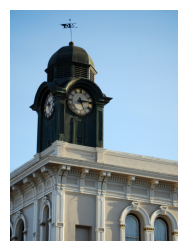

- A white building with a dark clock tower.
- two white and black clocks a black clock tower and white building
- Large building with clock tower on sunny day.
- A clock tower ring above an ornate building in the foreground.
- A clock that is at the top of a building.


In [5]:
plt.figure(figsize=(4, 3))
plt.imshow(plt.imread(image_paths[0])); plt.axis("off")
plt.show()
print("\n".join("- " + c for c in captions[subset_ids[0]]))

**Split by image.** The images are split into train (80 %), validation (10 %) and test (10 %) now, before anything else, so that nothing computed later can see the validation or test images. The split is by image, not by caption: an image has five captions, and splitting the captions would let the model train on one caption of an image and be tested on another caption of the same image.

The image at position `i` of the shuffled list goes to validation if `i % 10 == 8`, to test if `i % 10 == 9`, and to train otherwise. If the subset grows later, the images already used keep their set.

In [6]:
train_ids, val_ids, test_ids = split_ids(subset_ids)
splits = {"train": train_ids, "validation": val_ids, "test": test_ids}
print("images  :", {name: len(ids) for name, ids in splits.items()})
print("captions:", {name: sum(len(captions[i]) for i in ids) for name, ids in splits.items()})

assert not (set(train_ids) & set(val_ids) | set(train_ids) & set(test_ids) | set(val_ids) & set(test_ids))
assert set(train_ids) | set(val_ids) | set(test_ids) == set(subset_ids)
big = split_ids(choose_subset(captions.keys(), 3 * SUBSET_SIZE))       # with a bigger subset, the images keep their set
assert set(train_ids) <= set(big[0]) and set(val_ids) <= set(big[1]) and set(test_ids) <= set(big[2])
print("checks: no image in two sets, nothing lost, same sets with a bigger subset")

images  : {'train': 1600, 'validation': 200, 'test': 200}
captions: {'train': 8005, 'validation': 1000, 'test': 1001}
checks: no image in two sets, nothing lost, same sets with a bigger subset


## 3. Text preprocessing

A network reads numbers, so each caption becomes a list of integers of the same length:

1. lower case, punctuation removed;
2. `<start>` and `<end>` are added: the decoder starts from `<start>`, and `<end>` tells it when to stop;
3. a vocabulary is built from the **training captions only**: the most frequent words keep their own integer, the others become `<unk>`, and 0 is `<pad>`;
4. the captions are cut or padded to a common length, to make batches.

In [7]:
def caption_list(image_ids):
    """Captions of these images with <start> and <end>, and the image id of each caption."""
    texts, owners = [], []
    for image_id in image_ids:
        for caption in captions[image_id]:
            texts.append("<start> " + caption + " <end>")
            owners.append(image_id)
    return texts, owners


train_texts, train_owner = caption_list(train_ids)
val_texts, val_owner = caption_list(val_ids)
test_texts, test_owner = caption_list(test_ids)
print(len(train_texts), len(val_texts), len(test_texts), "captions (train, validation, test)")

8005 1000 1001 captions (train, validation, test)


How many words to keep? We count the words of the training captions and look at the share of all the word occurrences covered by the K most frequent ones.

4,248 different words, 1,907 of them appear only once
K = 500: covers 88.4 % of the occurrences
K = 1000: covers 93.8 % of the occurrences
K = 2000: covers 97.4 % of the occurrences
K = 3000: covers 98.7 % of the occurrences
K = 4000: covers 99.8 % of the occurrences


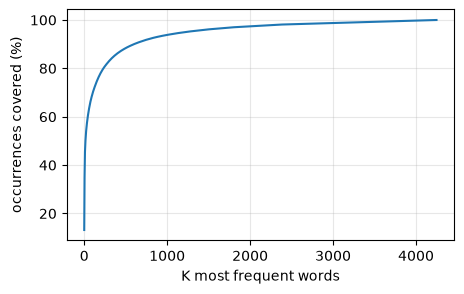

In [8]:
FILTERS = '!"#$%&()*+.,-/:;=?@[\\]^_`{|}~ '     # punctuation removed, except < > (the markers) and the apostrophe
count_tokenizer = tf.keras.preprocessing.text.Tokenizer(oov_token="<unk>", filters=FILTERS)
count_tokenizer.fit_on_texts(train_texts)

word_counts = sorted(count_tokenizer.word_counts.values(), reverse=True)
coverage = np.cumsum(word_counts) / sum(word_counts)
print(f"{len(word_counts):,} different words, {sum(c == 1 for c in word_counts):,} of them appear only once")
for k in (500, 1000, 2000, 3000, 4000):
    print(f"K = {k}: covers {100 * coverage[k - 1]:.1f} % of the occurrences")

plt.figure(figsize=(5, 3))
plt.plot(100 * coverage)
plt.xlabel("K most frequent words"); plt.ylabel("occurrences covered (%)"); plt.grid(alpha=0.3)
plt.show()

We keep **K = 2,000** words: they cover 97.4 % of the occurrences. The other words become `<unk>`; almost half of the 4,248 words appear only once, and the model cannot learn a word from one example. A bigger K would also make the last layer of the decoder bigger. With `num_words=K` the integers go from 0 to K - 1: 0 is `<pad>` and 1 is `<unk>`.

In [9]:
VOCAB_SIZE = 2000
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token="<unk>", filters=FILTERS)
tokenizer.fit_on_texts(train_texts)        # the vocabulary comes from the training captions only
tokenizer.word_index["<pad>"] = 0
tokenizer.index_word[0] = "<pad>"
UNK_ID, END_ID = tokenizer.word_index["<unk>"], tokenizer.word_index["<end>"]

train_seqs = tokenizer.texts_to_sequences(train_texts)
val_seqs = tokenizer.texts_to_sequences(val_texts)
test_seqs = tokenizer.texts_to_sequences(test_texts)
assert max(max(s) for s in train_seqs + val_seqs + test_seqs) < VOCAB_SIZE

print("words   :", train_texts[0])
print("integers:", train_seqs[0])
print("back    :", " ".join(tokenizer.index_word[i] for i in train_seqs[0]))

words   : <start> A white building with a dark clock tower. <end>
integers: [3, 2, 22, 66, 9, 2, 378, 70, 152, 4]
back    : <start> a white building with a dark clock tower <end>


Padding every caption to the longest one (43 words) would fill most positions with `<pad>`, so we pad to the **99th percentile** of the training lengths. The longer captions are cut and still end with `<end>`.

training lengths: median 12, 99th percentile 21, maximum 43


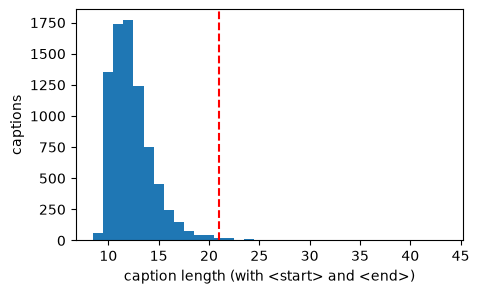

shapes: (8005, 21) (1000, 21) (1001, 21) | 0.8 % of the training captions are cut
train: 2.61 % of the words are <unk>
validation: 4.89 % of the words are <unk>
test: 4.34 % of the words are <unk>


In [10]:
train_lengths = np.array([len(s) for s in train_seqs])
MAX_LENGTH = int(np.percentile(train_lengths, 99))
print(f"training lengths: median {int(np.median(train_lengths))}, 99th percentile {MAX_LENGTH}, maximum {train_lengths.max()}")

plt.figure(figsize=(5, 3))
plt.hist(train_lengths, bins=range(train_lengths.min(), train_lengths.max() + 2), align="left")
plt.axvline(MAX_LENGTH, color="red", linestyle="--")
plt.xlabel("caption length (with <start> and <end>)"); plt.ylabel("captions")
plt.show()


def to_fixed_length(sequences):
    """Cut the captions longer than MAX_LENGTH (keeping <end> at the end), then pad with 0."""
    cut = [s if len(s) <= MAX_LENGTH else s[:MAX_LENGTH - 1] + [END_ID] for s in sequences]
    return tf.keras.preprocessing.sequence.pad_sequences(cut, maxlen=MAX_LENGTH, padding="post", value=0)


train_cap, val_cap, test_cap = to_fixed_length(train_seqs), to_fixed_length(val_seqs), to_fixed_length(test_seqs)
print("shapes:", train_cap.shape, val_cap.shape, test_cap.shape, f"| {100 * np.mean(train_lengths > MAX_LENGTH):.1f} % of the training captions are cut")
assert (train_cap[np.arange(len(train_cap)), np.minimum(train_lengths, MAX_LENGTH) - 1] == END_ID).all()   # all still end with <end>

for name, seqs in [("train", train_seqs), ("validation", val_seqs), ("test", test_seqs)]:
    print(f"{name}: {100 * np.mean(np.concatenate(seqs) == UNK_ID):.2f} % of the words are <unk>")

## 4. Image features

A pre-trained CNN (InceptionV3, trained on ImageNet) turns each image into a grid of features. We remove its classification layers and freeze it: 2,000 images are too few to train a CNN, and what it learned on ImageNet already helps. For a 299 x 299 image the grid is 8 x 8 = **64 regions of 2,048 numbers**, which the decoder will look at through the attention.

Since the CNN is frozen, the features of an image never change: we compute them once and save them in `cache/inceptionv3/` in `float16`, so the training epochs only read small files.

The images are resized to 299 x 299 (squashed, as in Deliverables 1 and 2) and given to the `preprocess_input` of InceptionV3, which puts the pixels in [-1, 1]. Here the original images go straight to 299 x 299; the effect of using the 128 x 128 images and the denoiser is measured later.

In [11]:
BACKBONE = {
    "name": "inceptionv3",
    "input_size": 299,
    "preprocess": tf.keras.applications.inception_v3.preprocess_input,    # pixels 0-255 in, [-1, 1] out
    "grid": (8, 8),
    "channels": 2048,
}
N_REGIONS = BACKBONE["grid"][0] * BACKBONE["grid"][1]
FEATURE_DIR = Path("cache") / BACKBONE["name"]       # one folder per backbone
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

encoder_cnn = tf.keras.applications.InceptionV3(include_top=False, weights="imagenet",
                                                input_shape=(BACKBONE["input_size"],) * 2 + (3,))
encoder_cnn.trainable = False
assert encoder_cnn.output_shape[1:] == BACKBONE["grid"] + (BACKBONE["channels"],)


def load_image(path, image_id):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, (BACKBONE["input_size"],) * 2, antialias=True)
    return BACKBONE["preprocess"](image), image_id


def compute_features(image_batch):
    """(batch, 64, 2048) features of a batch of preprocessed images."""
    grid = encoder_cnn(image_batch, training=False)
    return tf.reshape(grid, (grid.shape[0], N_REGIONS, BACKBONE["channels"]))


def make_dataset_of_images(paths, ids, batch_size=16):
    ds = tf.data.Dataset.from_tensor_slices((paths, ids)).map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def feature_file(image_id):
    return FEATURE_DIR / f"{image_id}.npy"

Check on one batch of 16 images, then the time for 20 images (after a warm-up call of the same size, since the first call is slower).

In [12]:
images, ids = next(iter(make_dataset_of_images(image_paths[:16], subset_ids[:16])))
features = compute_features(images)
print("images:", images.shape, f"| pixels in [{float(tf.reduce_min(images)):.1f}, {float(tf.reduce_max(images)):.1f}]")
print("features:", features.shape)

warm_up, _ = next(iter(make_dataset_of_images(image_paths[:20], subset_ids[:20], batch_size=20)))
compute_features(warm_up)
start = time.time()
for batch, _ in make_dataset_of_images(image_paths[20:40], subset_ids[20:40], batch_size=20):
    compute_features(batch).numpy()
seconds = time.time() - start
print(f"20 images: {seconds:.2f} s -> {len(subset_ids)} images in about {seconds / 20 * len(subset_ids) / 60:.1f} min")

images: (16, 299, 299, 3) | pixels in [-1.0, 1.0]
features: (16, 64, 2048)
20 images: 0.32 s -> 2000 images in about 0.5 min


Every image that is not yet in the cache is processed, so the cell can be run again after an interruption without redoing what is done.

In [13]:
def save_features(image_id, features):
    """Save in float16. Written under a temporary name first, so an interrupted run never leaves a half-written file."""
    final = feature_file(image_id)
    tmp = final.with_name(final.name + ".part")
    with open(tmp, "wb") as f:
        np.save(f, features.astype(np.float16))
    tmp.replace(final)


todo = [(i, p) for i, p in zip(subset_ids, image_paths) if not feature_file(i).exists()]
print(f"{len(subset_ids) - len(todo)} images already in the cache, {len(todo)} to process")

start = time.time()
if todo:
    todo_ids, todo_paths = [i for i, _ in todo], [p for _, p in todo]
    for batch, batch_ids in make_dataset_of_images(todo_paths, todo_ids):
        for image_id, f in zip(batch_ids.numpy(), compute_features(batch).numpy()):
            save_features(int(image_id), f)
print(f"done in {time.time() - start:.0f} s")

2000 images already in the cache, 0 to process
done in 0 s


In [14]:
files = [feature_file(i) for i in subset_ids]
print(f"files: {sum(f.exists() for f in files)}/{len(files)} | size on disk: {sum(f.stat().st_size for f in files) / 1e6:.0f} MB")

sample = np.load(files[0])
print("one file:", files[0].name, sample.shape, sample.dtype)
assert sample.shape == (N_REGIONS, BACKBONE["channels"]) and sample.dtype == np.float16
print("all values finite (200 files):", bool(np.isfinite(np.stack([np.load(f) for f in files[:200]])).all()))

# The saved features of the first 16 images against a new computation: the difference is small (float16 rounding and GPU arithmetic).
saved = np.stack([np.load(feature_file(int(i))) for i in ids.numpy()]).astype(np.float32)
difference = np.abs(features.numpy() - saved)
print(f"difference with a new computation: mean {difference.mean():.5f} (mean feature value {saved.mean():.3f}), largest {difference.max():.3f}")
assert difference.mean() < 0.01 * saved.mean()

files: 2000/2000 | size on disk: 525 MB
one file: 29586.npy (64, 2048) float16
all values finite (200 files): True
difference with a new computation: mean 0.00124 (mean feature value 0.345), largest 0.073


Our run: about 15 ms per image, so 30 seconds for the 2,000 images, and 525 MB of files. The small difference with a new computation (0.1 % on average) comes from the `float16` rounding and from the GPU arithmetic: features computed on another machine will be very close to ours, not identical.

## 5. The captioning model

The model writes the caption one word at a time.

- **Encoder:** a `Dense(256)` + ReLU on each of the 64 regions.
- **Attention (Bahdanau):** at each step, it scores the 64 regions against the memory of the decoder (its hidden state). A softmax turns the scores into weights that sum to 1, and the **context vector** is the average of the regions with these weights: this is how the model chooses where to look.
- **Decoder:** the context vector is concatenated with the embedding of the previous word (a learned vector of 256 numbers per word) and given to a **GRU**, a recurrent layer whose hidden state (512 numbers) remembers the words already written. Two `Dense` layers (512, then one score per word of the vocabulary) give the scores of the next word.

**Teacher forcing.** In training, the input of each step is the real previous word of the caption, not the model's own prediction. The loop over the words is written in the `call` method of the model, so that `model.fit` can train it.

**Loss.** Cross-entropy of each step, averaged over the real words only: the `<pad>` positions are masked.

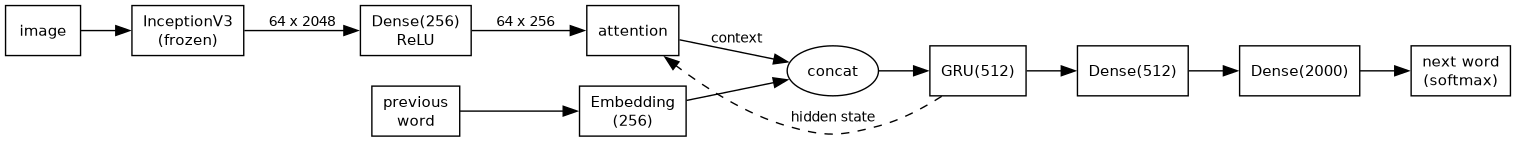

In [15]:
ARCHITECTURE_DOT = r"""
digraph model {
    rankdir=LR;
    node [shape=box, fontname="Helvetica", fontsize=11];
    edge [fontname="Helvetica", fontsize=10];

    image [label="image"];
    cnn [label="InceptionV3\n(frozen)"];
    encoder [label="Dense(256)\nReLU"];
    attention [label="attention"];
    word [label="previous\nword"];
    embedding [label="Embedding\n(256)"];
    concat [label="concat", shape=ellipse];
    gru [label="GRU(512)"];
    dense1 [label="Dense(512)"];
    dense2 [label="Dense(2000)"];
    out [label="next word\n(softmax)"];

    image -> cnn;
    cnn -> encoder [label="64 x 2048"];
    encoder -> attention [label="64 x 256"];
    attention -> concat [label="context"];
    word -> embedding -> concat;
    concat -> gru -> dense1 -> dense2 -> out;
    gru -> attention [label="hidden state", style=dashed, constraint=false];
}
"""
Path("reports").mkdir(exist_ok=True)
subprocess.run(["dot", "-Tpng", "-Gdpi=100", "-o", "reports/d3_captioning_architecture.png"], input=ARCHITECTURE_DOT, text=True, check=True)
ShowImage("reports/d3_captioning_architecture.png")

In [16]:
EMBEDDING_DIM, UNITS = 256, 512


class FeatureEncoder(keras.layers.Layer):
    """Dense + ReLU on each region: (batch, 64, 2048) -> (batch, 64, 256)."""
    def __init__(self, embedding_dim):
        super().__init__()
        self.fc = keras.layers.Dense(embedding_dim, activation="relu")

    def call(self, features):
        return self.fc(features)


class BahdanauAttention(keras.layers.Layer):
    """Weights over the 64 regions from the regions and the hidden state, and the weighted average (context)."""
    def __init__(self, units):
        super().__init__()
        self.W1 = keras.layers.Dense(units)
        self.W2 = keras.layers.Dense(units)
        self.V = keras.layers.Dense(1)

    def call(self, features, hidden):
        hidden = hidden[:, None, :]                                           # (batch, 1, 512): same state for every region
        score = self.V(tf.nn.tanh(self.W1(features) + self.W2(hidden)))       # (batch, 64, 1)
        weights = tf.nn.softmax(score, axis=1)                                # sums to 1 over the 64 regions
        context = tf.reduce_sum(weights * features, axis=1)                   # (batch, 256)
        return context, weights


class Decoder(keras.layers.Layer):
    """One decoding step: gives the scores of the next word."""
    def __init__(self, vocab_size, embedding_dim, units):
        super().__init__()
        self.attention = BahdanauAttention(units)
        self.embedding = keras.layers.Embedding(vocab_size, embedding_dim)
        self.gru = keras.layers.GRU(units, return_sequences=True, return_state=True)
        self.fc1 = keras.layers.Dense(units)
        self.fc2 = keras.layers.Dense(vocab_size)

    def call(self, word, features, hidden):
        context, weights = self.attention(features, hidden)
        step_input = tf.concat([context, self.embedding(word)], axis=-1)[:, None, :]    # (batch, 1, 512): a sequence of one step
        output, hidden = self.gru(step_input, initial_state=hidden)
        scores = self.fc2(self.fc1(output[:, 0, :]))                                    # (batch, vocab_size)
        return scores, hidden, weights


class CaptionModel(keras.Model):
    """Image features and real caption in, scores of every next word out."""
    def __init__(self, vocab_size, embedding_dim, units):
        super().__init__()
        self.units = units
        self.encoder = FeatureEncoder(embedding_dim)
        self.decoder = Decoder(vocab_size, embedding_dim, units)

    def call(self, inputs):
        features, caption = inputs                                   # (batch, 64, 2048) and (batch, MAX_LENGTH)
        features = self.encoder(features)
        hidden = tf.zeros((tf.shape(caption)[0], self.units))        # empty memory at the start
        all_scores = []
        for step in range(caption.shape[1] - 1):
            # Teacher forcing: the input is the REAL word at this position of the caption.
            scores, hidden, _ = self.decoder(caption[:, step], features, hidden)
            all_scores.append(scores)
        return tf.stack(all_scores, axis=1)                          # (batch, MAX_LENGTH - 1, vocab_size)


def masked_loss(real_words, scores):
    """Cross-entropy averaged over the real words (the <pad> positions, 0, are ignored)."""
    loss = keras.losses.sparse_categorical_crossentropy(real_words, scores, from_logits=True)
    mask = tf.cast(real_words != 0, tf.float32)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)

For each caption, the features of its image are read from the cache (one small file at a time: the dataset is never loaded whole in memory). The caption is given as the input of the steps (all the words but the last) and as the expected output (all the words but the first): the word to predict at a step is the one that follows the input word.

In [17]:
def load_features(image_id):
    return np.load(feature_file(int(image_id))).astype(np.float32)


def make_caption_dataset(owner_ids, caption_array, batch_size=BATCH_SIZE, training=False):
    """Dataset of ((features, caption), expected words), one element per caption."""
    ds = tf.data.Dataset.from_tensor_slices((np.array(owner_ids, dtype=np.int64), caption_array))
    if training:
        ds = ds.shuffle(len(owner_ids), seed=SEED, reshuffle_each_iteration=True)    # new order at each epoch

    def to_example(image_id, caption):
        features = tf.numpy_function(load_features, [image_id], tf.float32)
        features.set_shape((N_REGIONS, BACKBONE["channels"]))
        return (features, caption), caption[1:]

    return ds.map(to_example, num_parallel_calls=tf.data.AUTOTUNE).batch(batch_size).prefetch(tf.data.AUTOTUNE)


train_ds = make_caption_dataset(train_owner, train_cap, training=True)
val_ds = make_caption_dataset(val_owner, val_cap)
test_ds = make_caption_dataset(test_owner, test_cap)

(features_batch, caption_batch), expected_batch = next(iter(make_caption_dataset(train_owner, train_cap)))
print("features:", features_batch.shape, "| caption:", caption_batch.shape, "| expected words:", expected_batch.shape)
print("caption :", " ".join(tokenizer.index_word[int(i)] for i in caption_batch[0]))
print("expected:", " ".join(tokenizer.index_word[int(i)] for i in expected_batch[0]))

features: (16, 64, 2048) | caption: (16, 21) | expected words: (16, 20)
caption : <start> a white building with a dark clock tower <end> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>
expected: a white building with a dark clock tower <end> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad> <pad>


**Check on one batch.** The shapes at each stage of one decoding step, then the whole model. Before any training the model knows nothing, so its loss should be close to that of a uniform guess among the 2,000 words, `ln(2000)`. A very different value would mean a bug.

In [18]:
keras.utils.set_random_seed(SEED)
caption_model = CaptionModel(VOCAB_SIZE, EMBEDDING_DIM, UNITS)

hidden = tf.zeros((features_batch.shape[0], UNITS))
first_word = caption_batch[:, 0]                                   # <start>
encoded = caption_model.encoder(features_batch)
context, weights = caption_model.decoder.attention(encoded, hidden)
embedded = caption_model.decoder.embedding(first_word)
scores, new_hidden, _ = caption_model.decoder(first_word, encoded, hidden)
all_scores = caption_model((features_batch, caption_batch))

print("encoder  :", features_batch.shape, "->", encoded.shape)
print("attention: weights", weights.shape, f"(sum {float(tf.reduce_sum(weights[0])):.1f}) | context", context.shape)
print("embedding:", first_word.shape, "->", embedded.shape)
print("one step : scores", scores.shape, "| hidden state", new_hidden.shape)
print("all steps:", all_scores.shape, "= (batch, MAX_LENGTH - 1, VOCAB_SIZE)")

encoder  : (16, 64, 2048) -> (16, 64, 256)
attention: weights (16, 64, 1) (sum 1.0) | context (16, 256)
embedding: (16,) -> (16, 256)
one step : scores (16, 2000) | hidden state (16, 512)
all steps: (16, 20, 2000) = (batch, MAX_LENGTH - 1, VOCAB_SIZE)


In [19]:
caption_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=masked_loss)

loss = float(masked_loss(expected_batch, all_scores))
print(f"loss before training: {loss:.3f} | ln({VOCAB_SIZE}) = {np.log(VOCAB_SIZE):.3f}")

# Mask check: changing the scores at the <pad> positions must not change the loss.
is_pad = tf.cast(expected_batch == 0, tf.float32)[:, :, None]
changed = float(masked_loss(expected_batch, all_scores + 5.0 * is_pad))
print(f"{float(tf.reduce_mean(is_pad)):.0%} of the positions are <pad> | loss with other scores there: {changed:.3f}")
assert abs(changed - loss) < 1e-4

for name, layer in [("encoder Dense(256)", caption_model.encoder), ("attention", caption_model.decoder.attention),
                    ("embedding", caption_model.decoder.embedding), ("GRU(512)", caption_model.decoder.gru),
                    ("Dense(512)", caption_model.decoder.fc1), ("Dense(2000)", caption_model.decoder.fc2)]:
    print(f"{name:20s} {layer.count_params():>10,} parameters")
caption_model.summary()

loss before training: 7.583 | ln(2000) = 7.601
40% of the positions are <pad> | loss with other scores there: 7.583
encoder Dense(256)      524,544 parameters
attention               394,753 parameters
embedding               512,000 parameters
GRU(512)              1,575,936 parameters
Dense(512)              262,656 parameters
Dense(2000)           1,026,000 parameters


Model: "caption_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ feature_encoder                 │ ?                      │       524,544 │
│ (FeatureEncoder)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Decoder)               │ ?                      │     3,771,345 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,295,889 (16.39 MB)

 Trainable params: 4,295,889 (16.39 MB)

 Non-trainable params: 0 (0.00 B)

The model has **4,295,889 parameters**, all trainable (the CNN is not part of it). The largest block is the GRU (1.58 million), then the last `Dense` layer (1.03 million): it has one output per word, so it grows with `VOCAB_SIZE`, and with 5,000 words it would be the largest. The loss before training (7.58) is close to `ln(2000)` = 7.60, and the mask works. The summary shows `?` for the output shapes of the encoder and the decoder because Keras does not follow what happens inside a layer called in a loop; the shapes are the ones printed above.